# EV Plug Occupancy Forecaster: final demo

**INSE 6450 · AI in Systems Engineering · Fall 2026**
Kaoutar Eoukich · Mehdi Sabor · Jamal Eddine El Betioui

This notebook follows the presentation slide by slide, from the raw charging sessions to monitoring and the human in the loop.

| Part | Presenter | In this notebook |
|---|---|---|
| 1 · Problem formulation | Kaoutar | **live**: counts the raw sessions |
| 2 · Feature engineering | Mehdi | **live**: rebuilds the 15-min occupancy table and the windows from the raw JSON |
| 3 · Model benchmarking | Jamal | saved benchmark (`outputs/benchmark_*`) |
| 4 · CQR | Jamal | **live**: DLinear forecasts + conformal intervals |
| 5 · DLinear / ensemble | Mehdi | **live**: trend/residual split, Ridge, the ensemble |
| 6 · Stress testing | Kaoutar | **live**: corrupts the test inputs and re-scores |
| 7 · Robustness | Jamal | **live** abstention + saved attack results (`outputs/tables`) |
| 8 · Monitoring | Mehdi | saved replays (`outputs/monitoring`): runs A (real), B (faults), C (drift) |
| 9 · Drift & continual learning | Jamal | saved replay (`outputs/continual`) |
| 10 · HITL & active learning | Kaoutar, Jamal | saved replay (`outputs/continual`, `outputs/hitl`) |

**Live** cells recompute the result in a few seconds from the saved data and models. The long experiments (training, 127-day replays) are loaded from the files their own notebooks saved.

**How to run:** open this notebook from the repository root, with the packages in `README.md` installed, and choose *Restart Kernel and Run All*. It takes about one minute on a laptop CPU.

## 0. Setup

In [1]:
import glob, json, os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch
import torch.nn as nn
import joblib
import holidays
from numpy.lib.stride_tricks import sliding_window_view as swv
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")          # sklearn version warnings when loading the saved Ridge
sys.path.insert(0, "src")
from model_selection.conformal import conformalize

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

SITES = ["caltech", "jpl"]
LOCAL_TZ = "America/Los_Angeles"
FREQ = "15min"
L, H = 672, 16                     # 1 week of history -> 4 hours ahead
SCALE_WINDOW, SCALE_EPS = 96, 0.5  # each window is divided by its last-day mean + 0.5
CAL_COLS = ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_holiday"]
torch.set_num_threads(1)

# Saved datasets (made by data_audit.ipynb)
data = {s: dict(np.load(f"outputs/{s}_occupancy_data.npz")) for s in SITES}
for s in SITES:
    print(s, {k: data[s][k].shape for k in ["train_X_hist", "val_X_hist", "test_X_hist", "test_y"]})

caltech {'train_X_hist': (56461, 672), 'val_X_hist': (12087, 672), 'test_X_hist': (12102, 672), 'test_y': (12102, 16)}
jpl {'train_X_hist': (57242, 672), 'val_X_hist': (12255, 672), 'test_X_hist': (12270, 672), 'test_y': (12270, 16)}


In [2]:
class DLinear(nn.Module):
    """DLinear with a calendar term and 3 quantile outputs (same as src/models/train_neural.py)."""
    def __init__(self, seq_len=L, horizon=H, cal_dim=5, kernel=25, n_q=3):
        super().__init__()
        self.seasonal = nn.Linear(seq_len, horizon * n_q)   # linear layer on the residual
        self.trend = nn.Linear(seq_len, horizon * n_q)      # linear layer on the trend
        self.calendar = nn.Linear(cal_dim, n_q)             # calendar of each target step
        self.kernel, self.horizon, self.n_q = kernel, horizon, n_q

    def decompose(self, x):
        p = (self.kernel - 1) // 2
        xp = nn.functional.pad(x.unsqueeze(1), (p, p), mode="replicate")
        trend = nn.functional.avg_pool1d(xp, self.kernel, stride=1).squeeze(1)  # moving average
        return trend, x - trend

    def forward(self, x, cal):
        trend, resid = self.decompose(x)
        out = (self.seasonal(resid) + self.trend(trend)).reshape(-1, self.horizon, self.n_q)
        return torch.sort(out + self.calendar(cal), dim=-1).values   # q10 <= q50 <= q90


def window_scale(hist):
    return hist[:, -SCALE_WINDOW:].mean(axis=1, keepdims=True) + SCALE_EPS


def dlinear_forecast(model, hist, cal, batch=4096):
    """Quantile forecasts in cars, shape (N, 16, 3)."""
    scale = window_scale(hist)
    x = (hist / scale).astype(np.float32)
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch):
            out.append(model(torch.from_numpy(x[i:i + batch]),
                             torch.from_numpy(cal[i:i + batch].astype(np.float32))).numpy())
    return np.concatenate(out) * scale[:, :, None]


def load_dlinear(site, robust=False):
    m = DLinear()
    path = f"outputs/dlinear_{site}{'_robust' if robust else ''}.pt"
    m.load_state_dict(torch.load(path, map_location="cpu"))
    return m.eval()


def mae(y, p): return float(np.abs(y - p).mean())
def coverage(y, lo, hi): return float(((y >= lo) & (y <= hi)).mean())

models = {s: load_dlinear(s) for s in SITES}
print("DLinear parameters:", sum(p.numel() for p in models["caltech"].parameters()))

DLinear parameters: 64626


---
## 1 · Problem formulation (Kaoutar)

*Will there be a free plug when I arrive?*

* **Input:** the last 7 days of occupancy (672 steps of 15 min) plus the calendar of the next 4 hours.
* **Model:** a quantile forecaster that predicts the 10th, 50th and 90th percentiles.
* **Output:** 16 forecasts over 4 hours, each with an 80% interval.

**Success criteria:** beat persistence and seasonal-naive on MAE and RMSE, 80% intervals that really cover about 80%, and under 1 second per forecast.

The data is real sessions from two campus garages (ACN-Data, CC BY 4.0), one JSON file per site per month.

In [3]:
def load_raw(data_dir="acn_dataset"):
    frames = []
    for p in sorted(glob.glob(os.path.join(data_dir, "acn_*.json"))):
        with open(p) as f:
            df = pd.DataFrame(json.load(f))
        if len(df):
            df["site"] = "caltech" if "caltech" in os.path.basename(p) else "jpl"
            frames.append(df)
    return pd.concat(frames, ignore_index=True)

raw = load_raw()
first = pd.to_datetime(raw["connectionTime"], utc=True).dt.tz_convert(LOCAL_TZ)
summary = (raw.assign(first=first).groupby("site")
           .agg(sessions=("sessionID", "size"), first_session=("first", "min"), last_session=("first", "max")))
print(f"{len(raw):,} charging sessions, {raw.shape[1] - 1} fields each, {raw['site'].nunique()} sites")
summary

44,989 charging sessions, 13 fields each, 2 sites


,sessions,first_session,last_session
site,,,
caltech,16126,2018-12-31 21:28:34-08:00,2021-09-13 18:52:37-07:00
jpl,28863,2019-01-01 17:00:51-08:00,2021-09-13 22:43:39-07:00


---
## 2 · Feature engineering (Mehdi)

### 2.1 The data as we found it
The first five Caltech sessions, exactly as stored. App inputs (`userInputs`) are a nested list and are missing for some sessions.

In [4]:
cols = ["connectionTime", "disconnectTime", "kWhDelivered", "stationID", "userInputs"]
print("Sessions without app inputs: %.1f%%" % (100 * raw["userInputs"].isna().mean()))
raw[raw.site == "caltech"][cols].head(5)

Sessions without app inputs: 6.9%


,connectionTime,disconnectTime,kWhDelivered,stationID,userInputs
0,2018-12-31 21:28:34-08:00,2018-12-31 22:03:12-08:00,3.250,2-39-130-31,"[{'userID': 1616, 'milesRequested': 20, 'WhPer..."
1,2019-01-01 09:41:45-08:00,2019-01-01 10:39:21-08:00,0.900,2-39-138-566,None
2,2019-01-01 10:09:17-08:00,2019-01-01 18:39:32-08:00,12.534,2-39-79-379,"[{'userID': 558, 'milesRequested': 80, 'WhPerM..."
3,2019-01-01 10:39:25-08:00,2019-01-01 11:18:49-08:00,0.883,2-39-138-566,None
4,2019-01-01 11:18:53-08:00,2019-01-01 12:14:07-08:00,0.879,2-39-138-566,None


### 2.2 What we did to the data
1. **Load** one JSON per site per month; times to UTC.
2. **Clean**: drop duplicate sessions and impossible rows (missing or negative duration, stuck sessions); keep long stays, because a long stay really blocks a plug.
3. **Count cars**: round each arrival *down* and each departure *up* to the 15-min grid, then take a running total.
4. **Add the calendar**: hour and weekday as sin/cos, plus the California holiday flag.
5. **Drop dead periods**: runs of 5+ days at zero occupancy (COVID shutdown, logging gaps).
6. **Cut windows**: 672 steps back, 16 ahead.
7. **Split by time**: 70 / 15 / 15, removing windows whose targets cross into the next split.

The code below is the same as `data_audit.ipynb`.

In [5]:
def clean_sessions(raw):
    df = raw.copy()
    for c in ["connectionTime", "disconnectTime"]:
        df[c] = pd.to_datetime(df[c], utc=True, errors="coerce")
    dur_h = (df["disconnectTime"] - df["connectionTime"]).dt.total_seconds() / 3600
    missing = df["connectionTime"].isna() | df["disconnectTime"].isna()
    negative = dur_h <= 0
    stuck = (dur_h > 72) & (df["kWhDelivered"] < 0.5)
    n0 = len(df)
    df = df.drop_duplicates("sessionID")
    df = df[~(missing | negative | stuck).reindex(df.index)]
    print(f"rows: {n0:,} -> {len(df):,} ({n0 - len(df)} removed)")
    return df


def occupancy_series(d, freq=FREQ):
    """Cars plugged in per 15-min step: arrival rounded down, departure rounded up."""
    start, end = d["connectionTime"].min().floor(freq), d["disconnectTime"].max().ceil(freq)
    grid = pd.date_range(start, end, freq=freq)
    arrivals = d["connectionTime"].dt.floor(freq).value_counts().reindex(grid, fill_value=0)
    departures = d["disconnectTime"].dt.ceil(freq).value_counts().reindex(grid, fill_value=0)
    return (arrivals - departures).cumsum().rename("occupancy")


CA_HOLIDAYS = holidays.US(state="CA")

def build_table(occ):
    loc = occ.index.tz_convert(LOCAL_TZ)
    hour = np.asarray(loc.hour + loc.minute / 60)
    dow = np.asarray(loc.dayofweek)
    return pd.DataFrame({
        "occupancy": occ.values,
        "hour_sin": np.sin(2 * np.pi * hour / 24), "hour_cos": np.cos(2 * np.pi * hour / 24),
        "dow_sin": np.sin(2 * np.pi * dow / 7), "dow_cos": np.cos(2 * np.pi * dow / 7),
        "is_holiday": [int(day in CA_HOLIDAYS) for day in loc.date],
    }, index=occ.index)


sessions = clean_sessions(raw)
tables = {s: build_table(occupancy_series(g)) for s, g in sessions.groupby("site")}
for s, t in tables.items():
    print(f"{s}: {len(t):,} rows of 15 min, max {int(t.occupancy.max())} cars, missing values: {int(t.isna().sum().sum())}")

rows: 44,989 -> 44,989 (0 removed)


caltech: 94,745 rows of 15 min, max 38 cars, missing values: 0
jpl: 94,713 rows of 15 min, max 56 cars, missing values: 0


### 2.3 One step = 15 minutes: how occupancy is counted
The three cars from the slide. A car counts in every 15-min step it touches.

In [6]:
toy = pd.DataFrame({
    "car": ["A", "B", "C"],
    "connectionTime": pd.to_datetime(["2021-01-04 08:07", "2021-01-04 08:20", "2021-01-04 09:20"], utc=True),
    "disconnectTime": pd.to_datetime(["2021-01-04 08:52", "2021-01-04 09:40", "2021-01-04 11:00"], utc=True),
})
toy_occ = occupancy_series(toy)
toy_occ.loc["2021-01-04 08:00":"2021-01-04 09:45"].to_frame().T.rename(columns=lambda t: t.strftime("%H:%M"))

,08:00,08:15,08:30,08:45,09:00,09:15,09:30,09:45
occupancy,1,2,2,2,1,2,2,1


### 2.4 The new table: one row every 15 minutes
Real Caltech rows (local time). On 31 Dec the first car leaves; 1 Jan is a holiday; on 9 Jan the morning arrivals fill the garage.

In [7]:
t = tables["caltech"].copy()
t.index = t.index.tz_convert(LOCAL_TZ)
picks = ["2018-12-31 21:15", "2018-12-31 22:15", "2019-01-01 10:30", "2019-01-09 08:00",
         "2019-01-09 08:30", "2019-01-09 09:00", "2019-01-09 09:45"]
t.loc[[pd.Timestamp(p, tz=LOCAL_TZ) for p in picks]].round(2)

,occupancy,hour_sin,hour_cos,dow_sin,dow_cos,is_holiday
2018-12-31 21:15:00-08:00,1,-0.66,0.75,0.00,1.00,0
2018-12-31 22:15:00-08:00,0,-0.44,0.90,0.00,1.00,0
2019-01-01 10:30:00-08:00,3,0.38,-0.92,0.78,0.62,1
2019-01-09 08:00:00-08:00,2,0.87,-0.50,0.97,-0.22,0
2019-01-09 08:30:00-08:00,10,0.79,-0.61,0.97,-0.22,0
2019-01-09 09:00:00-08:00,16,0.71,-0.71,0.97,-0.22,0
2019-01-09 09:45:00-08:00,19,0.56,-0.83,0.97,-0.22,0


### 2.5 Drop dead periods, cut windows, split by time
Then we check that the windows rebuilt here are **identical** to the ones saved in `outputs/*_occupancy_data.npz`, which all models were trained on.

In [8]:
def gap_mask(occ, min_days=5):
    zero = (occ == 0).astype(int)
    edges = np.flatnonzero(np.diff(np.r_[0, zero, 0]))
    gap = np.zeros(len(zero), dtype=bool)
    for a, b in zip(edges[::2], edges[1::2]):
        if b - a >= min_days * 96:
            gap[a:b] = True
    return gap


def valid_origins(gap):
    c = np.r_[0, np.cumsum(gap)]
    o = np.arange(L, len(gap) - H + 1)
    return o[(c[o + H] - c[o - L]) == 0]


def split_origins(o, fracs=(0.70, 0.15, 0.15)):
    i1, i2 = int(len(o) * fracs[0]), int(len(o) * (fracs[0] + fracs[1]))
    tr, va, te = o[:i1], o[i1:i2], o[i2:]
    t1, t2 = va[0], te[0]
    return {"train": tr[tr + H <= t1], "val": va[(va >= t1) & (va + H <= t2)], "test": te}


rows = []
for s, tab in tables.items():
    occ = tab["occupancy"].to_numpy("float32")
    sp = split_origins(valid_origins(gap_mask(occ)))
    X_test = swv(occ, L)[sp["test"] - L]
    same = np.array_equal(X_test, data[s]["test_X_hist"])
    rows.append({"site": s, **{k: len(v) for k, v in sp.items()}, "identical to saved windows": same})
pd.DataFrame(rows).set_index("site")

,train,val,test,identical to saved windows
site,,,,
caltech,56461,12087,12102,True
jpl,57242,12255,12270,True


### 2.6 Each sample: one week back, four hours ahead
History = 672 steps of occupancy only (known at forecast time). Target = the next 16 steps. Calendar = 5 features for each of the 16 target steps.

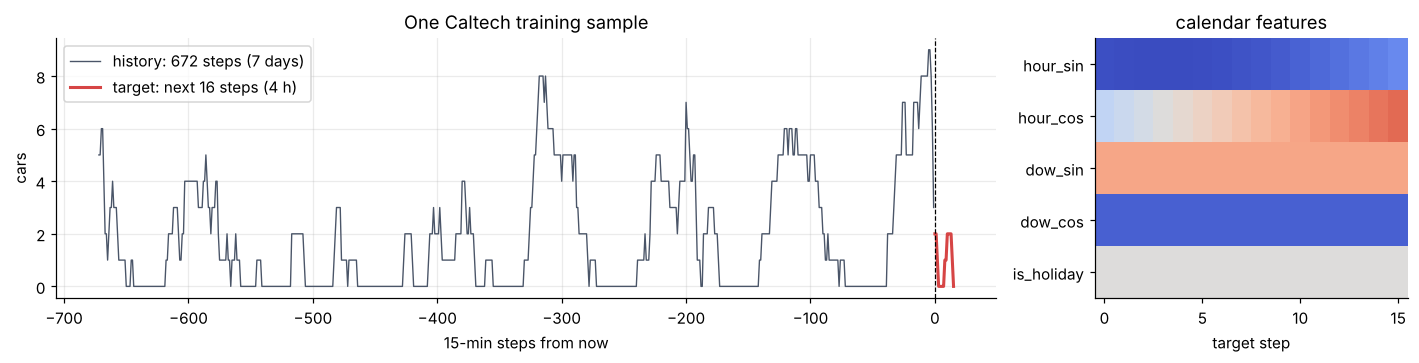

In [9]:
i = 5000
d = data["caltech"]
hist, y, cal = d["test_X_hist"][i], d["test_y"][i], d["test_X_cal"][i]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw={"width_ratios": [3, 1]})
ax[0].plot(np.arange(-L, 0), hist, color="#4a5568", lw=0.9, label="history: 672 steps (7 days)")
ax[0].plot(np.arange(0, H), y, color="#d64545", lw=2, label="target: next 16 steps (4 h)")
ax[0].axvline(0, color="k", ls="--", lw=0.8); ax[0].set_xlabel("15-min steps from now"); ax[0].set_ylabel("cars")
ax[0].set_title("One Caltech training sample"); ax[0].legend(loc="upper left")
ax[1].imshow(cal.T, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
ax[1].set_yticks(range(5)); ax[1].set_yticklabels(CAL_COLS); ax[1].set_xlabel("target step")
ax[1].set_title("calendar features"); ax[1].grid(False)
plt.tight_layout(); plt.show()

---
## 3 · Model benchmarking (Jamal)
Five models, two sites. MAE in plugs over all 16 steps of the test set; latency for one forecast on CPU (p50), from `python -m src.benchmark_models`.

In [10]:
names = {"dlinear": "DLinear (selected)", "gru": "GRU", "ridge": "Ridge regression",
         "persistence": "Persistence", "seasonal_naive": "Seasonal naive"}
bench = {s: json.load(open(f"outputs/benchmark_{s}/benchmark_results.json")) for s in SITES}
rows = []
for key, name in names.items():
    r = {"model": name}
    for s in SITES:
        m = bench[s]["models"][key]
        rt = m["runtimes"].get("cpu_fp32") or m["runtimes"].get("cpu_numpy")
        r[f"{s} MAE"] = round(rt["accuracy"]["mae"], 3)
        r[f"{s} RMSE"] = round(rt["accuracy"]["rmse"], 3)
    m = bench["caltech"]["models"][key]
    rt = m["runtimes"].get("cpu_fp32") or m["runtimes"].get("cpu_numpy")
    r["CPU latency p50 (ms)"] = round(rt["single"]["p50_ms"], 3)
    r["parameters"] = m["parameters"]
    r["train time (s)"] = round(m["training"]["total_s"], 1) if m.get("training") and m["training"].get("total_s") else None
    rows.append(r)
pd.DataFrame(rows).set_index("model")

,caltech MAE,caltech RMSE,jpl MAE,jpl RMSE,CPU latency p50 (ms),parameters,train time (s)
model,,,,,,,
DLinear (selected),0.921,1.365,1.806,3.108,0.155,64626,22.4
GRU,0.880,1.367,1.903,3.714,6.942,17539,90.4
Ridge regression,0.957,1.363,1.995,3.046,0.125,12048,27.2
Persistence,1.213,2.091,3.249,6.234,0.004,0,NaN
Seasonal naive,1.217,1.977,3.174,6.285,0.001,0,NaN


**Why DLinear:** about as accurate as the GRU (best on JPL), but 0.15 ms per forecast on CPU instead of about 7 ms, 22 s to train, and 64,626 parameters. On a GPU a single forecast is slower (about 8 ms of data transfer), so we serve on CPU.

In [11]:
m = bench["caltech"]["models"]["dlinear"]["runtimes"]
pd.DataFrame({k: {"p50 latency (ms)": round(v["single"]["p50_ms"], 3), "MAE": round(v["accuracy"]["mae"], 4)}
              for k, v in m.items()}).T

,p50 latency (ms),MAE
cpu_fp32,0.155,0.9206
cpu_int8,0.298,0.9225
cuda_fp32,8.352,0.9206


---
## 4 · CQR: intervals that really cover 80% (Jamal)
The raw 10–90% band of the model is too narrow. **Split conformal quantile regression** measures, on the validation windows, how far the truth falls outside the band, and widens every test band by that amount, separately for each of the 16 steps.

The numbers below use the checkpoints in `outputs/dlinear_*.pt` (the model used in parts 5–8). The slide shows the benchmark run of part 3, so the values differ by about one point.

In [12]:
fc = {}
rows = []
for s in SITES:
    d = data[s]
    v = dlinear_forecast(models[s], d["val_X_hist"], d["val_X_cal"])
    t = dlinear_forecast(models[s], d["test_X_hist"], d["test_X_cal"])
    lo, hi = conformalize(d["val_y"], v[..., 0], v[..., 2], t[..., 0], t[..., 2])
    fc[s] = {"val": v, "test": t, "lo": lo, "hi": hi}
    y = d["test_y"]
    rows.append({"site": s, "MAE": round(mae(y, t[..., 1]), 3),
                 "raw 80% coverage": f"{coverage(y, t[..., 0], t[..., 2]):.1%}",
                 "CQR 80% coverage": f"{coverage(y, lo, hi):.1%}",
                 "raw width (cars)": round(float((t[..., 2] - t[..., 0]).mean()), 2),
                 "CQR width (cars)": round(float((hi - lo).mean()), 2)})
pd.DataFrame(rows).set_index("site")

,MAE,raw 80% coverage,CQR 80% coverage,raw width (cars),CQR width (cars)
site,,,,,
caltech,0.904,61.1%,76.7%,2.13,2.83
jpl,1.844,70.3%,80.0%,5.47,6.26


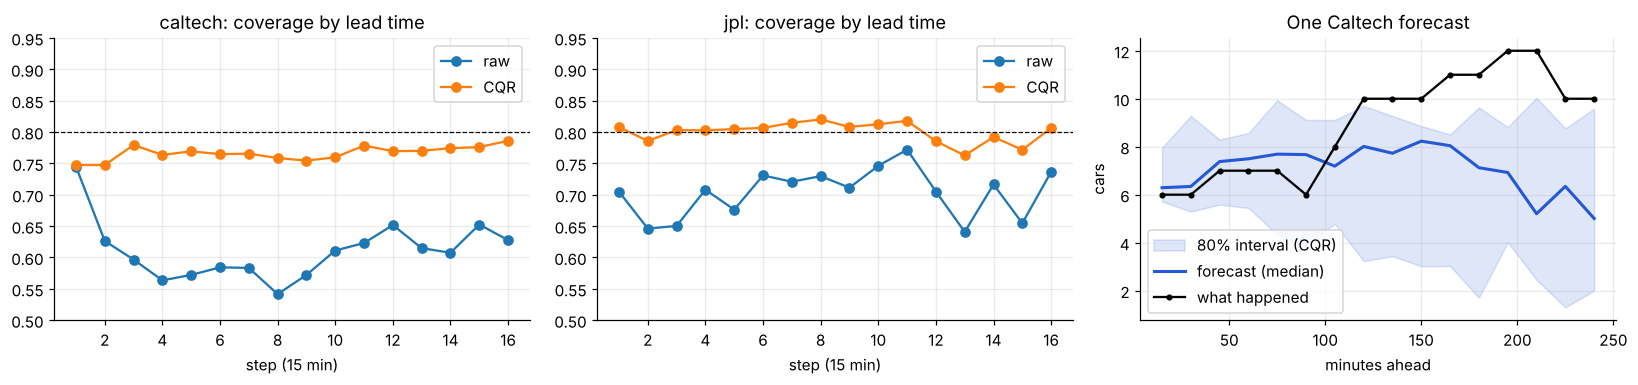

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for k, s in enumerate(SITES):
    y, t = data[s]["test_y"], fc[s]["test"]
    ax[k].plot(range(1, 17), ((y >= t[..., 0]) & (y <= t[..., 2])).mean(0), "o-", label="raw")
    ax[k].plot(range(1, 17), ((y >= fc[s]["lo"]) & (y <= fc[s]["hi"])).mean(0), "o-", label="CQR")
    ax[k].axhline(0.8, color="k", ls="--", lw=0.8); ax[k].set_ylim(0.5, 0.95)
    ax[k].set_title(f"{s}: coverage by lead time"); ax[k].set_xlabel("step (15 min)"); ax[k].legend()
# one forecast, as a user would see it
s, i = "caltech", 9000
y, t = data[s]["test_y"][i], fc[s]["test"][i]
x = np.arange(1, 17) * 15
ax[2].fill_between(x, fc[s]["lo"][i], fc[s]["hi"][i], color="#2458d6", alpha=0.15, label="80% interval (CQR)")
ax[2].plot(x, t[:, 1], color="#2458d6", lw=2, label="forecast (median)")
ax[2].plot(x, y, "k.-", label="what happened")
ax[2].set_xlabel("minutes ahead"); ax[2].set_ylabel("cars"); ax[2].set_title("One Caltech forecast"); ax[2].legend()
plt.tight_layout(); plt.show()

**Caveat:** the guarantee assumes the future looks like the past. Time series drift, so coverage is *measured* in monitoring, not promised.

---
## 5 · DLinear and the ensemble (Mehdi)

### 5.1 DLinear splits the week into trend and the rest
1. Divide the 672 steps by the last-day mean + 0.5, so busy and quiet weeks look alike.
2. **Trend** = moving average over 25 steps (about 6 h). **Residual** = history − trend.
3. One linear layer per part (672 → 16 × 3) plus a calendar term, then multiply back.

Weakness: the moving average reacts slowly, so it lags at step 1 (for example, a Monday surge after a quiet weekend).

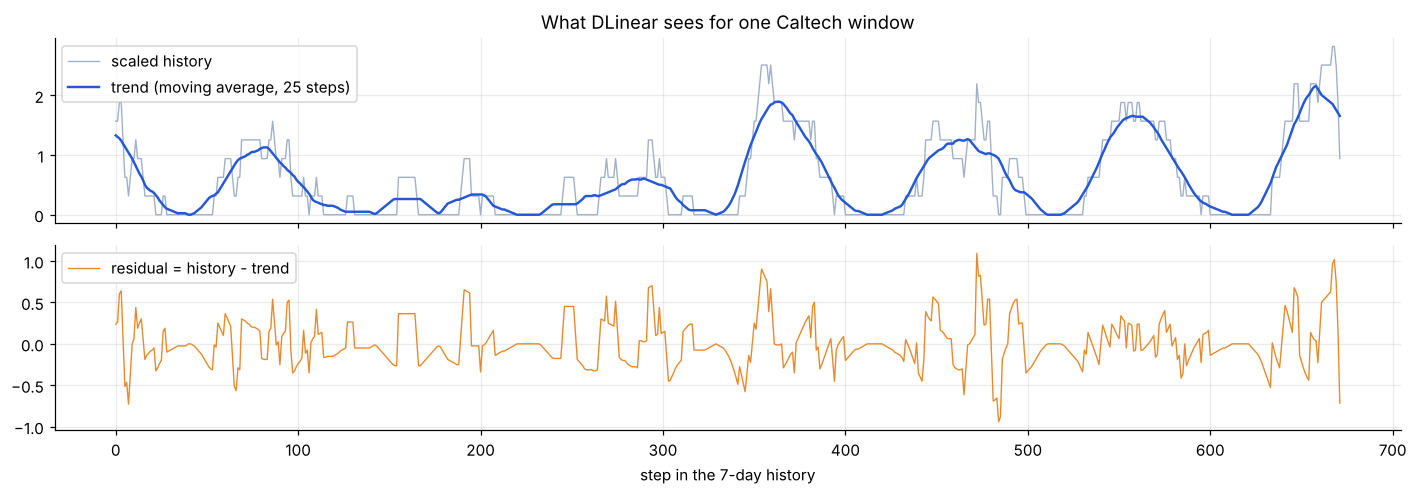

seasonal layer: (48, 672) | trend layer: (48, 672) | calendar layer: (3, 5)


In [14]:
i = 5000
h = data["caltech"]["test_X_hist"][i:i + 1]
xs = torch.from_numpy((h / window_scale(h)).astype(np.float32))
trend, resid = (a.numpy()[0] for a in models["caltech"].decompose(xs))
fig, ax = plt.subplots(2, 1, figsize=(13, 4.6), sharex=True)
ax[0].plot(xs.numpy()[0], color="#9fb0c8", lw=0.9, label="scaled history")
ax[0].plot(trend, color="#2458d6", lw=1.6, label="trend (moving average, 25 steps)")
ax[1].plot(resid, color="#e8892b", lw=0.9, label="residual = history - trend")
for a in ax: a.legend(loc="upper left")
ax[1].set_xlabel("step in the 7-day history"); ax[0].set_title("What DLinear sees for one Caltech window")
plt.tight_layout(); plt.show()
w = models["caltech"]
print("seasonal layer:", tuple(w.seasonal.weight.shape), "| trend layer:", tuple(w.trend.weight.shape),
      "| calendar layer:", tuple(w.calendar.weight.shape))

### 5.2 Ridge fixes the first-step lag
Ridge regression on the raw 672 steps + 16 × 5 calendar values (752 standardized features, `alpha = 10`) puts heavy weight on the latest steps, so it is good just ahead and weaker later. DLinear is the opposite. Combining them helps most at 15 minutes.

The slide's numbers come from `src/benchmark_robustness.py`: the final forecast is the **average of the two medians**, the interval keeps DLinear's half-width around it, and CQR is applied on top.

In [15]:
ridge = {s: joblib.load(f"outputs/benchmark_{s}/ridge.joblib") for s in SITES}

def ridge_forecast(s, hist, cal):
    feats = np.concatenate([hist, cal.reshape(len(cal), -1)], axis=1)
    return ridge[s]["model"].predict(ridge[s]["scaler"].transform(feats))

def ensemble(dl, rd):
    point = 0.5 * (dl[..., 1] + rd)
    half = 0.5 * (dl[..., 2] - dl[..., 0])
    return np.maximum(point - half, 0), point, point + half

def latency_ms(fn, n=200):
    h, c = data["caltech"]["test_X_hist"][:1], data["caltech"]["test_X_cal"][:1]
    for _ in range(20): fn(h, c)
    t0 = time.perf_counter()
    for _ in range(n): fn(h, c)
    return (time.perf_counter() - t0) / n * 1000

rows, per_h = [], {}
for s in SITES:
    d, y = data[s], data[s]["test_y"]
    rd_v, rd_t = ridge_forecast(s, d["val_X_hist"], d["val_X_cal"]), ridge_forecast(s, d["test_X_hist"], d["test_X_cal"])
    v_lo, v_pt, v_hi = ensemble(fc[s]["val"], rd_v)
    t_lo, t_pt, t_hi = ensemble(fc[s]["test"], rd_t)
    e_lo, e_hi = conformalize(d["val_y"], v_lo, v_hi, t_lo, t_hi)
    fc[s].update(ridge=rd_t, ens=t_pt, ens_lo=e_lo, ens_hi=e_hi, ridge_val=rd_v)
    dl = fc[s]["test"][..., 1]
    for name, p, lo, hi in [("DLinear", dl, fc[s]["lo"], fc[s]["hi"]), ("DLinear + Ridge", t_pt, e_lo, e_hi)]:
        rows.append({"site": s, "model": name, "MAE, all 16 steps": round(mae(y, p), 3),
                     "MAE, 15 min ahead": round(mae(y[:, 0], p[:, 0]), 3),
                     "80% coverage (CQR)": f"{coverage(y, lo, hi):.1%}"})
    per_h[s] = {"DLinear": np.abs(y - dl).mean(0), "Ridge": np.abs(y - rd_t).mean(0), "DLinear + Ridge": np.abs(y - t_pt).mean(0)}

m = models["caltech"]
dl_ms = latency_ms(lambda h, c: dlinear_forecast(m, h, c))
en_ms = latency_ms(lambda h, c: ensemble(dlinear_forecast(m, h, c), ridge_forecast("caltech", h, c)))
res = pd.DataFrame(rows).set_index(["site", "model"]).astype(object)
for s in SITES:
    a, b = res.loc[(s, "DLinear")], res.loc[(s, "DLinear + Ridge")]
    for col in ["MAE, all 16 steps", "MAE, 15 min ahead"]:
        res.loc[(s, "DLinear + Ridge"), col] = f"{b[col]} ({(b[col] - a[col]) / a[col]:+.1%})"
print(f"time per forecast on this machine: DLinear {dl_ms:.2f} ms, DLinear + Ridge {en_ms:.2f} ms")
res

time per forecast on this machine: DLinear 0.06 ms, DLinear + Ridge 0.31 ms


MAE, all 16 steps MAE, 15 min ahead 80% coverage (CQR)
site    model                                                                 
caltech DLinear                     0.904             0.364              76.7%
        DLinear + Ridge       0.9 (-0.4%)     0.341 (-6.3%)              77.7%
jpl     DLinear                     1.844             0.729              80.0%
        DLinear + Ridge      1.79 (-2.9%)     0.58 (-20.4%)              81.5%

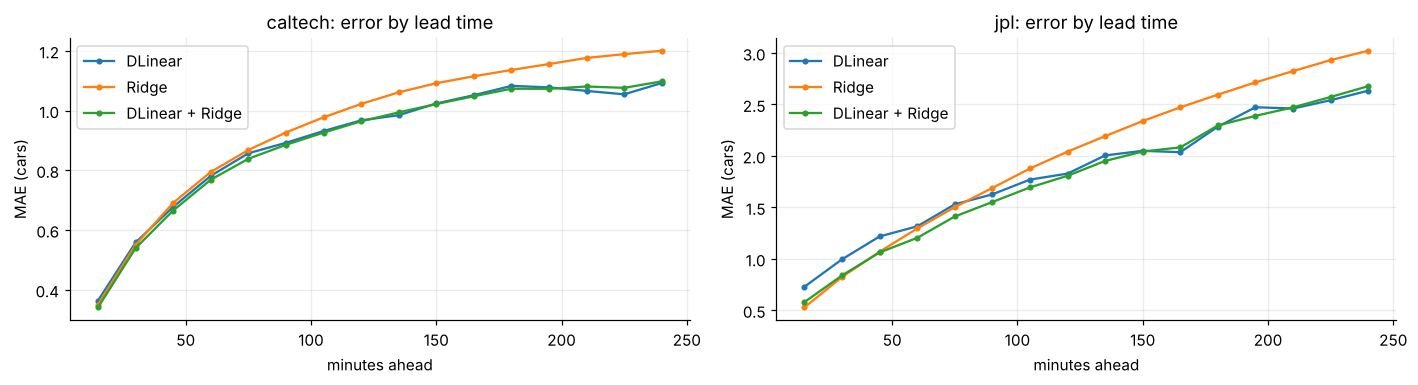

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for k, s in enumerate(SITES):
    for name, v in per_h[s].items():
        ax[k].plot(np.arange(1, 17) * 15, v, "o-", ms=3, label=name)
    ax[k].set_title(f"{s}: error by lead time"); ax[k].set_xlabel("minutes ahead"); ax[k].set_ylabel("MAE (cars)"); ax[k].legend()
plt.tight_layout(); plt.show()

**A learned meta-learner** (one small `Ridge(alpha=10, positive=True)` per lead time, fitted on validation forecasts, as in `continual_learning_hit.py`) gives the weights below. Ridge dominates just ahead and DLinear takes over at longer lead times.

In [17]:
rows = []
for s in SITES:
    d = data[s]
    for h in [0, 1, 3, 7, 11, 15]:
        meta = Ridge(alpha=10, positive=True).fit(np.c_[fc[s]["val"][:, h, 1], fc[s]["ridge_val"][:, h]], d["val_y"][:, h])
        rows.append({"site": s, "lead time": f"{(h + 1) * 15} min",
                     "weight DLinear": round(meta.coef_[0], 2), "weight Ridge": round(meta.coef_[1], 2)})
pd.DataFrame(rows).pivot(index="lead time", columns="site").reindex([f"{m} min" for m in [15, 30, 60, 120, 180, 240]])

weight DLinear       weight Ridge      
site             caltech   jpl      caltech   jpl
lead time                                        
15 min              0.25  0.15         0.70  0.85
30 min              0.44  0.25         0.46  0.74
60 min              0.40  0.53         0.42  0.47
120 min             0.46  0.47         0.32  0.49
180 min             0.47  0.57         0.26  0.39
240 min             0.52  0.43         0.26  0.48

---
## 6 · Stress testing (Kaoutar)
We corrupt the test inputs in five ways, three severities each, three seeds, and re-score DLinear (Caltech). Same corruptions as `dlinear_stresstest.ipynb`.

* **Gaussian noise**: sensor measurement noise (severity × training std).
* **Random dropout**: lost readings, filled with the training median.
* **Temporal masking**: a continuous outage of 1, 3 or 6 hours somewhere in the week.
* **Calendar feature loss**: 1, 2 or 5 calendar features replaced by their training mean.
* **OOD demand spike**: the last 4 hours of history inflated by 25%, 50% or 100%.

In [18]:
d = data["caltech"]
Xh, Xc, y = d["test_X_hist"], d["test_X_cal"], d["test_y"]
med, std, cmax = float(np.median(d["train_X_hist"])), float(d["train_X_hist"].std()), float(d["train_X_hist"].max())
cal_means = d["train_X_cal"].mean(axis=(0, 1))

def noise(h, s, rng):   return np.clip(h + rng.normal(0, s * std, h.shape).astype(np.float32), 0, None)
def dropout(h, s, rng): h = h.copy(); h[rng.random(h.shape) < s] = med; return h
def masking(h, hours, rng):
    h, k = h.copy(), int(hours * 4)
    starts = rng.integers(0, h.shape[1] - k + 1, len(h))
    idx = starts[:, None] + np.arange(k)
    np.put_along_axis(h, idx, med, axis=1); return h
def cal_loss(c, n): c = c.copy(); c[:, :, :n] = cal_means[:n]; return c
def spike(h, p): h = h.copy(); h[:, -16:] *= 1 + p; return np.clip(h, 0, cmax)

clean_mae = mae(y, dlinear_forecast(models["caltech"], Xh, Xc)[..., 1])
tests = {"Gaussian noise": ([0.05, 0.15, 0.30], lambda s, r: (noise(Xh, s, r), Xc)),
         "Random dropout": ([0.10, 0.30, 0.50], lambda s, r: (dropout(Xh, s, r), Xc)),
         "Temporal masking (h)": ([1, 3, 6], lambda s, r: (masking(Xh, s, r), Xc)),
         "Calendar feature loss (n)": ([1, 2, 5], lambda s, r: (Xh, cal_loss(Xc, s))),
         "OOD demand spike": ([0.25, 0.50, 1.00], lambda s, r: (spike(Xh, s), Xc))}
rows = []
for name, (levels, fn) in tests.items():
    for lev in levels:
        maes = [mae(y, dlinear_forecast(models["caltech"], *fn(lev, np.random.default_rng(seed)))[..., 1]) for seed in [42, 123, 456]]
        rows.append({"corruption": name, "severity": lev, "MAE": np.mean(maes),
                     "MAE increase (%)": 100 * (np.mean(maes) - clean_mae) / clean_mae})
stress = pd.DataFrame(rows)
print(f"clean MAE: {clean_mae:.3f}")
stress.round(3).set_index(["corruption", "severity"])

clean MAE: 0.904


MAE  MAE increase (%)
corruption                severity                         
Gaussian noise            0.05      0.950             5.038
                          0.15      1.171            29.498
                          0.30      1.611            78.248
Random dropout            0.10      1.016            12.415
                          0.30      1.239            37.024
                          0.50      1.470            62.576
Temporal masking (h)      1.00      0.908             0.432
                          3.00      0.912             0.894
                          6.00      0.915             1.221
Calendar feature loss (n) 1.00      0.917             1.482
                          2.00      0.934             3.315
                          5.00      0.936             3.544
OOD demand spike          0.25      1.090            20.608
                          0.50      1.412            56.175
                          1.00      2.196           142.968

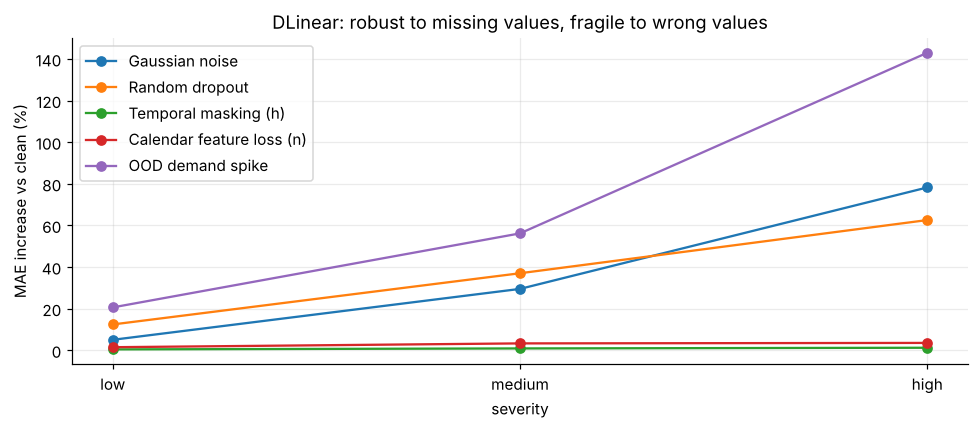

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, g in stress.groupby("corruption", sort=False):
    ax.plot([1, 2, 3], g["MAE increase (%)"], "o-", label=name)
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["low", "medium", "high"]); ax.set_xlabel("severity")
ax.set_ylabel("MAE increase vs clean (%)"); ax.set_title("DLinear: robust to missing values, fragile to wrong values"); ax.legend()
plt.tight_layout(); plt.show()

---
## 7 · Robustness (Jamal)

### 7.1 When the model is unsure, a human decides
The width of the CQR interval measures how unsure the model is. If the average width of a forecast is above a threshold τ (the 90th percentile of the widths, as in `src/benchmark_robustness.py`, so 10% of forecasts go to a human), the system does not act on its own and alerts the operator instead.

In [20]:
rows = []
for s in SITES:
    d = data[s]
    width = (fc[s]["hi"] - fc[s]["lo"]).mean(1)          # average CQR width of each forecast
    tau = float(np.quantile(width, 0.90))                # as in src/benchmark_robustness.py
    keep = width <= tau
    y, p = d["test_y"], fc[s]["test"][..., 1]
    fc[s]["abstain"] = ~keep
    rows.append({"site": s, "tau (cars)": round(tau, 2), "abstained": f"{(~keep).mean():.1%}",
                 "MAE, all forecasts": round(mae(y, p), 3), "MAE, kept forecasts": round(mae(y[keep], p[keep]), 3)})
pd.DataFrame(rows).set_index("site")

,tau (cars),abstained,"MAE, all forecasts","MAE, kept forecasts"
site,,,,
caltech,4.76,10.0%,0.904,0.816
jpl,11.72,10.0%,1.844,1.562


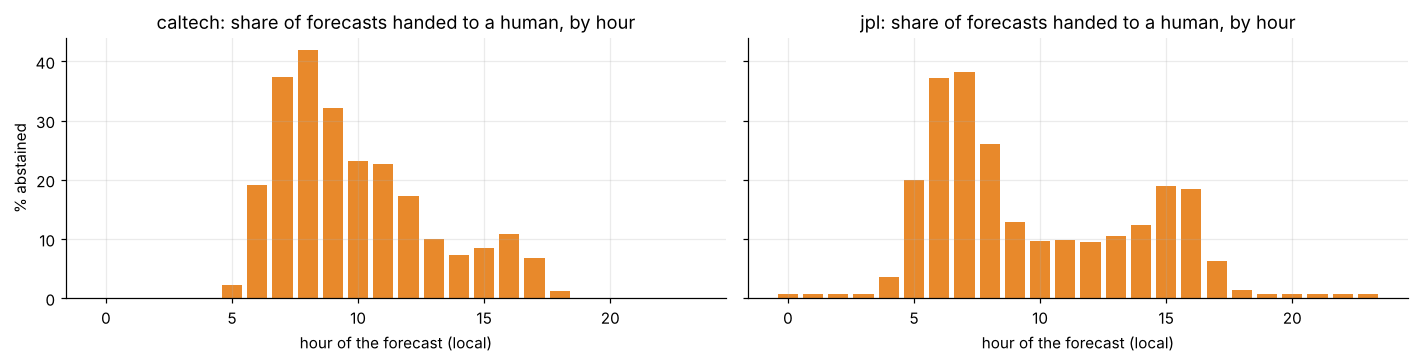

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
for k, s in enumerate(SITES):
    origin = pd.to_datetime(data[s]["timestamps"][data[s]["test_origins"]], utc=True).tz_convert(LOCAL_TZ)
    by_hour = pd.Series(fc[s]["abstain"]).groupby(origin.hour).mean() * 100
    ax[k].bar(by_hour.index, by_hour.values, color="#e8892b")
    ax[k].set_title(f"{s}: share of forecasts handed to a human, by hour"); ax[k].set_xlabel("hour of the forecast (local)")
ax[0].set_ylabel("% abstained"); plt.tight_layout(); plt.show()

### 7.2 The other defence layers, and the worst case
Saved results of `python src/benchmark_robustness.py` (test set, CQR intervals): jitter training (σ = 0.03), the input sanitizer (no NaN crash), the DLinear–Ridge ensemble, and a white-box attacker who knows the weights and nudges each value by at most 1 car (PGD-7).

In [22]:
keep_rows = {"Clean: Original Model (Conformal Split-CQR)": "Clean",
             "Corrupted Telemetry (Without Sanitizer)": "Missing values, no sanitizer",
             "Corrupted Telemetry (With InputSanitizer)": "Missing values + sanitizer",
             "Random Bounded Noise (eps=1.0 car) [Original Defenseless]": "Random noise ±1 car (faulty sensor)",
             "Random Bounded Noise (eps=1.0 car)": "Random noise ±1 car (faulty sensor)",
             "White-Box PGD-7 (eps=1.0 car) [Original Model Defenseless]": "PGD-7 attack",
             "White-Box PGD-7 Attack [With Stacking Ensemble Defense]": "PGD-7 vs the ensemble"}
out = {}
for s, path in [("caltech", "outputs/tables/benchmark_task_metrics_caltech.csv"), ("jpl", "outputs/tables/jpl/jpl_benchmark_task_metrics.csv")]:
    t = pd.read_csv(path).set_index("Test Condition")
    t = t.loc[[r for r in keep_rows if r in t.index]].rename(index=keep_rows)
    t = t[~t.index.duplicated()]
    out[(s, "MAE")] = t["MAE [95% CI]"].str.split(" ").str[0]
    out[(s, "80% coverage")] = t["Calibrated 80% Cov"]
pd.DataFrame(out).reindex(list(dict.fromkeys(keep_rows.values())))

caltech                  jpl             
                                        MAE 80% coverage     MAE 80% coverage
Test Condition                                                               
Clean                                0.9040        0.767  1.8437        0.800
Missing values, no sanitizer         FAILED        0.000  FAILED        0.000
Missing values + sanitizer           0.7654        0.760  1.7501        0.780
Random noise ±1 car (faulty sensor)  0.8345        0.725  1.7359        0.760
PGD-7 attack                         2.8234        0.249  4.5649        0.320
PGD-7 vs the ensemble                2.7970        0.166  4.3875        0.252

Natural noise is handled. Optimized attacks remain an open weakness: the real defence is authenticated ingestion plus range checks, which is what the data monitor in part 8 provides.

---
## 8 · Monitoring (Mehdi)
We watch the **data** first (every week, 12 checks against the last 4 good weeks), then the **model** (every day, once the real value is known 4 hours later). Every check ends as OK, WARN (logged), ALERT (team alerted or automatic fix) or TICKET (slow issue, plan a fix).

Saved results of `monitoring_data_quality.ipynb` and `monitoring_model_quality.ipynb`.

### 8.1 Data monitoring: what we check, when we warn or alert

In [23]:
spec = pd.read_csv("outputs/monitoring/check_specification.csv")
spec[["group", "check", "warn", "alert", "on_alert", "meaning"]].set_index(["group", "check"])

warn  alert on_alert                                            meaning
group        check                                                                                  
Schema       missing_fields  1.00   1.00     page  a required field is missing (e.g. renamed upst...
             new_fields      1.00    inf     page  an unknown field appeared (usually the other h...
Completeness null_pct        0.50   2.00     page  % of sessions with an empty required field (tr...
             volume_ratio    0.60   0.30     page  sessions this week / median of the last 4 good...
             dead_weekdays   1.00   2.00     page  working days with zero arrivals = ingestion ou...
Validity     invalid_pct     1.00   5.00     page  % impossible sessions (ends before start, kWh ...
             duplicate_pct   0.01   2.00     page                    % of session IDs received twice
Categories   new_ports       1.00   5.00     page  charging ports never seen before = capacity ch...
Drift        psi_vs_recent   0.10   0.25     page  occupancy distribution vs the last 4 good week...
             hour_corr       0.90   0.75     page  daily occupancy curve vs the last 4 good weeks...
             psi_vs_train    0.10   0.25   ticket  occupancy distribution vs training data (regim...
             psi_scale       0.10   0.25   ticket  model input scale s_i (trailing-day mean + 0.5...

### 8.2 Model monitoring: what we check, when we warn or alert
| Check | Window | WARN | ALERT | Then |
|---|---|---|---|---|
| MAE ÷ naive MAE | 7 days | > 0.75 | > 0.80 for 3 days | alert ML on-call + retraining ticket |
| MAE ÷ naive MAE | 7 days (2 for a new version) | | ≥ 1.00 for 3 days | automatic rollback to the last version |
| 80% interval coverage | 7 days | outside 77–83% | outside 75–85% | automatic recalibration on the last 7 days |
| p95 latency | per forecast | | > 50 ms | alert on-call, serve cached forecast |

Data is checked **week by week** (a week holds every weekday and enough sessions for drift measures). The model is scored **day by day** (the truth arrives 4 hours later, and a broken release must be caught within days).

### 8.3 We broke the data and the model on purpose, like this
* **Run A** replays the real data and the normal model v1: anything it flags is a false alarm.
* **Run B** replays the same Caltech weeks with 7 injected data faults (one every two weeks), and a broken release v2 on 8 June that multiplies by the scale one extra time.
* **Run C** keeps the data valid but injects a **drift** in driver behaviour, the same two drifts as the Milestone 3 and continual-learning experiments: every session 2.5 h later from 14 June (Time-of-Use pricing), then demand ×1.75 from 19 July. Both stay until the end.

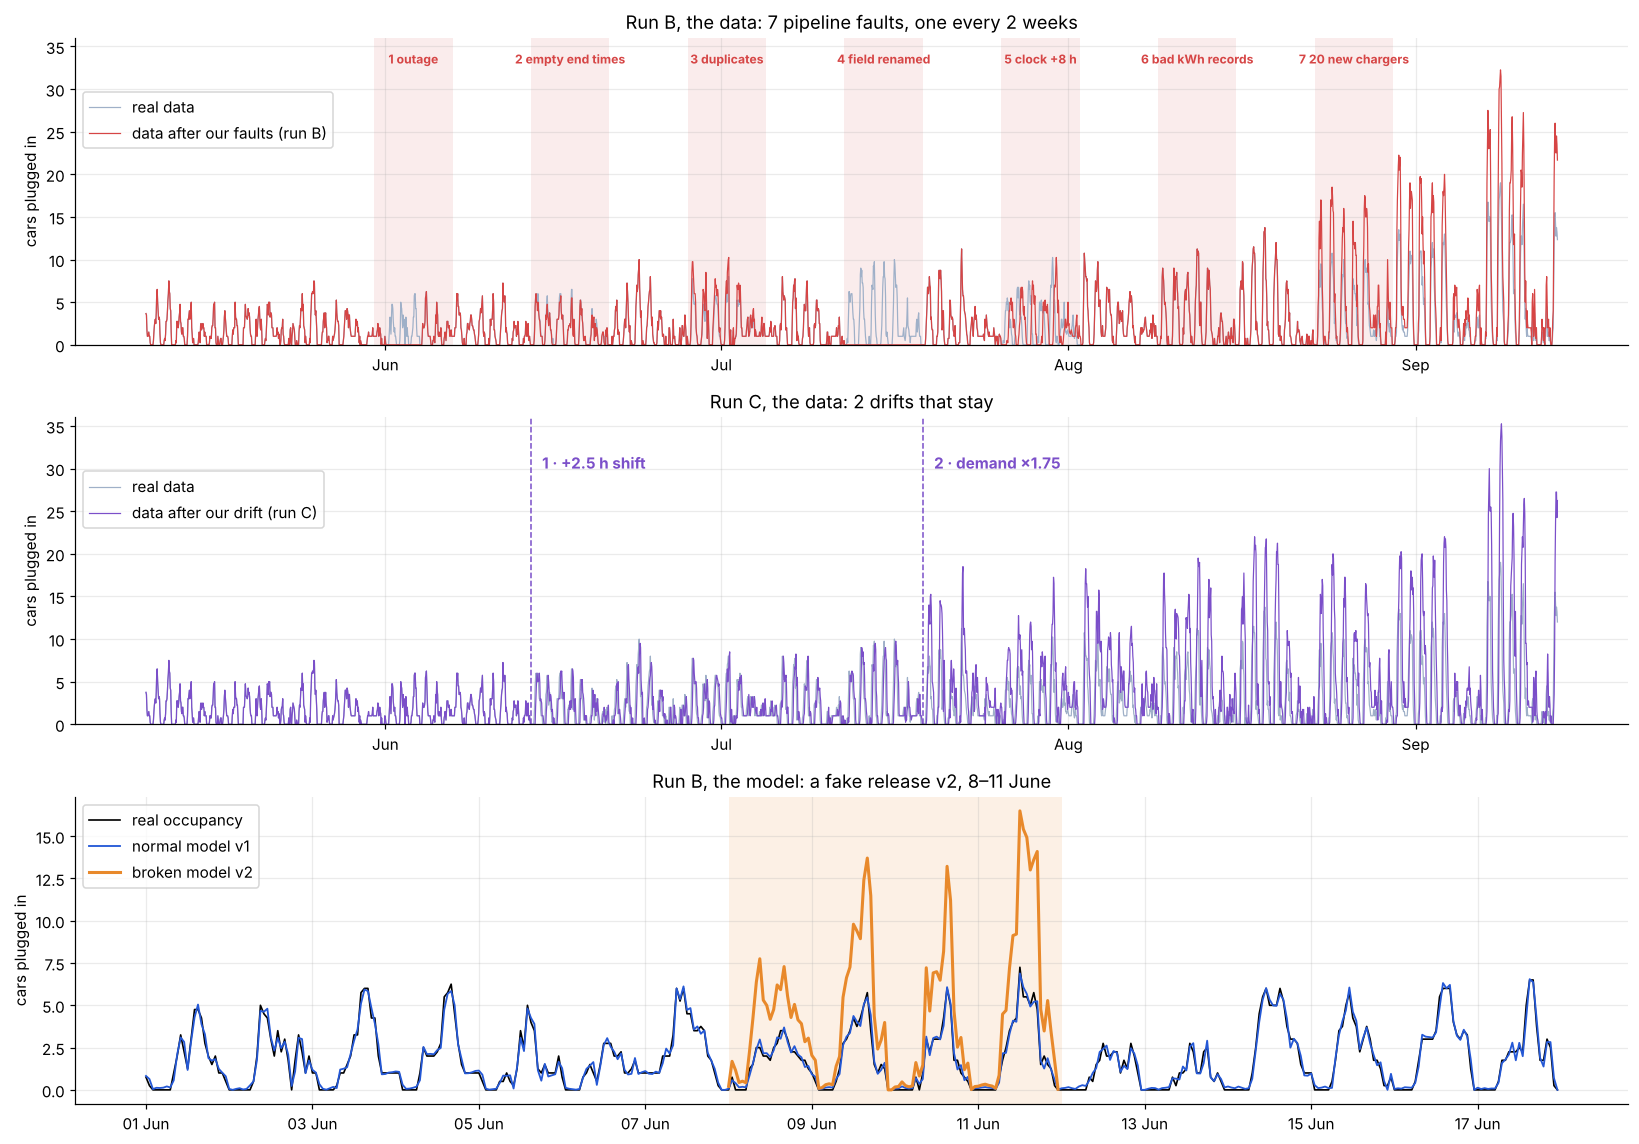

In [24]:
hs = pd.read_csv("outputs/monitoring/caltech_test_series_hourly.csv")
hs["t"] = pd.to_datetime(hs["t"].str[:19]); hs = hs.set_index("t")
faults = [("2021-05-31", "outage"), ("2021-06-14", "empty end times"), ("2021-06-28", "duplicates"), ("2021-07-12", "field renamed"),
          ("2021-07-26", "clock +8 h"), ("2021-08-09", "bad kWh records"), ("2021-08-23", "20 new chargers")]
drifts = [("2021-06-14", "1 · +2.5 h shift"), ("2021-07-19", "2 · demand ×1.75")]
fig, ax = plt.subplots(3, 1, figsize=(15, 10.5))
ax[0].plot(hs.index, hs["actual"], color="#9fb0c8", lw=0.8, label="real data")
ax[0].plot(hs.index, hs["broken"], color="#d64545", lw=0.8, label="data after our faults (run B)")
for k, (w, name) in enumerate(faults):
    a = pd.Timestamp(w); ax[0].axvspan(a, a + pd.Timedelta(days=7), color="#d64545", alpha=0.1, lw=0)
    ax[0].text(a + pd.Timedelta(days=3.5), 33, f"{k + 1} {name}", ha="center", color="#d64545", weight="bold", fontsize=8)
ax[0].set_title("Run B, the data: 7 pipeline faults, one every 2 weeks")
ax[1].plot(hs.index, hs["actual_rebuilt"], color="#9fb0c8", lw=0.8, label="real data")
ax[1].plot(hs.index, hs["drift"], color="#7b4fc9", lw=0.8, label="data after our drift (run C)")
for w, name in drifts:
    ax[1].axvline(pd.Timestamp(w), color="#7b4fc9", ls="--", lw=1)
    ax[1].text(pd.Timestamp(w) + pd.Timedelta(days=1), 30, name, color="#7b4fc9", weight="bold")
ax[1].set_title("Run C, the data: 2 drifts that stay")
for a in ax[:2]:
    a.set_ylim(0, 36); a.legend(loc="upper left", bbox_to_anchor=(0, 0.85))
    a.xaxis.set_major_locator(mdates.MonthLocator()); a.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
z = hs.loc["2021-06-01":"2021-06-17"]
v2 = (z.index >= "2021-06-08") & (z.index < "2021-06-12")
ax[2].plot(z.index, z["actual"], color="k", lw=1.1, label="real occupancy")
ax[2].plot(z.index, z["pred"], color="#2458d6", lw=1.2, label="normal model v1")
ax[2].plot(z.index[v2], z["pred_v2"][v2], color="#e8892b", lw=2, label="broken model v2")
ax[2].axvspan(pd.Timestamp("2021-06-08"), pd.Timestamp("2021-06-12"), color="#e8892b", alpha=0.12, lw=0)
ax[2].set_title("Run B, the model: a fake release v2, 8–11 June"); ax[2].legend(loc="upper left")
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
for a in ax: a.set_ylabel("cars plugged in")
plt.tight_layout(); plt.show()

### 8.4 Week by week: what the data monitor saw

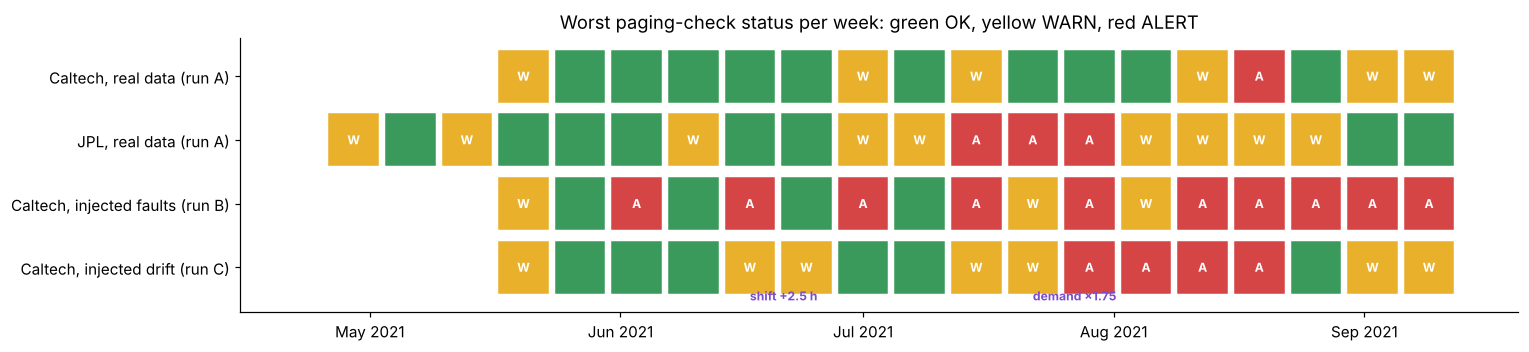

In [25]:
runs = {"Caltech, real data (run A)": "weekly_clean_caltech", "JPL, real data (run A)": "weekly_clean_jpl",
        "Caltech, injected faults (run B)": "weekly_injected_caltech", "Caltech, injected drift (run C)": "weekly_drift_caltech"}
paging = spec.loc[spec["on_alert"] == "page", "check"].tolist()
level = {"OK": 0, "WARN": 1, "ALERT": 2}
colors = {0: "#3a9a5b", 1: "#e8b02b", 2: "#d64545"}
fig, ax = plt.subplots(figsize=(14, 3.3))
for r, (label, f) in enumerate(runs.items()):
    w = pd.read_csv(f"outputs/monitoring/{f}.csv", parse_dates=["week"])
    worst = w[[f"s_{c}" for c in paging]].replace(level).apply(pd.to_numeric, errors="coerce").max(axis=1)
    for day, v in zip(w["week"], worst):
        ax.add_patch(plt.Rectangle((mdates.date2num(day), r - 0.4), 6, 0.8, color=colors[int(v)]))
        ax.text(mdates.date2num(day) + 3, r, ["", "W", "A"][int(v)], ha="center", va="center", color="w", fontsize=8, weight="bold")
for w, t in [("2021-06-14", "shift +2.5 h"), ("2021-07-19", "demand ×1.75")]:
    ax.annotate(t, (mdates.date2num(pd.Timestamp(w)) + 3, 3.45), color="#7b4fc9", fontsize=8, weight="bold", ha="left", va="center")
ax.set_yticks(range(4)); ax.set_yticklabels(runs.keys()); ax.set_ylim(3.7, -0.6)
ax.set_xlim(mdates.date2num(pd.Timestamp("2021-04-15")), mdates.date2num(pd.Timestamp("2021-09-20")))
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.grid(False)
ax.set_title("Worst paging-check status per week: green OK, yellow WARN, red ALERT")
plt.tight_layout(); plt.show()

**Did every check catch its problem?** One row per injected fault: the check that should fire, its status in run B, and the same week in run A.

In [26]:
pd.read_csv("outputs/monitoring/detection_matrix.csv").set_index("week")

,problem injected,check that should fire,its status,paged?,same week in run A,all checks that fired
week,,,,,,
2021-05-31,outage,dead_weekdays,ALERT,ALERT,OK,"volume_ratio, dead_weekdays, psi_vs_recent, ho..."
2021-06-14,null_burst,null_pct,ALERT,ALERT,OK,null_pct
2021-06-28,duplicates,duplicate_pct,ALERT,ALERT,WARN,"duplicate_pct, psi_vs_recent"
2021-07-12,schema_rename,missing_fields,ALERT,ALERT,WARN,"missing_fields, new_fields, null_pct, psi_vs_r..."
2021-07-26,clock_bug,hour_corr,ALERT,ALERT,OK,hour_corr
2021-08-09,corrupt_records,invalid_pct,ALERT,ALERT,WARN,"invalid_pct, psi_vs_recent"
2021-08-23,new_chargers,new_ports,ALERT,ALERT,OK,"new_ports, psi_vs_recent"


In [27]:
log = pd.read_csv("outputs/monitoring/alert_log.csv")
print(log.groupby("run").size().rename("alerts").to_string(), "\n")
log.head(10)

run
A real         7
B injected    14
C drift        4 



,run,site,week,check,value,threshold,action
0,B injected,caltech,2021-05-31,dead_weekdays,3.000,2.00,Page data engineering: check the ingestion job...
1,B injected,caltech,2021-05-31,psi_vs_recent,0.301,0.25,ML on-call: holiday? clock bug? If it lasts 2+...
2,B injected,caltech,2021-06-14,null_pct,14.563,2.00,Page data engineering: check the ingestion job...
3,B injected,caltech,2021-06-28,duplicate_pct,20.000,2.00,Ticket to data engineering: cleaning drops the...
4,B injected,caltech,2021-07-12,missing_fields,1.000,1.00,"Page data engineering: pause the model, serve ..."
5,B injected,caltech,2021-07-12,null_pct,100.000,2.00,Page data engineering: check the ingestion job...
6,B injected,caltech,2021-07-12,psi_vs_recent,5.131,0.25,ML on-call: holiday? clock bug? If it lasts 2+...
7,B injected,caltech,2021-07-26,hour_corr,-0.432,0.75,ML on-call: holiday? clock bug? If it lasts 2+...
8,B injected,caltech,2021-08-09,invalid_pct,8.451,5.00,Ticket to data engineering: cleaning drops the...
9,B injected,caltech,2021-08-16,psi_vs_recent,0.323,0.25,ML on-call: holiday? clock bug? If it lasts 2+...


**And the drift (run C)?** The drift checks, week by week, against the same weeks of real data.

In [28]:
a, c = (pd.read_csv(f"outputs/monitoring/{f}.csv") for f in ["weekly_clean_caltech", "weekly_drift_caltech"])
pd.DataFrame({
    "drift starts": c["week"].map({"2021-06-14": "shift +2.5 h", "2021-07-19": "demand ×1.75"}).fillna(""),
    "mean cars (A)": a["mean_occupancy"].round(2), "mean cars (C)": c["mean_occupancy"].round(2),
    "PSI vs last 4 wks (C)": c["psi_vs_recent"].round(3), "daily-curve corr. (C)": c["hour_corr"].round(3),
    "status (A)": a["page"], "status (C)": c["page"],
}).set_index(c["week"])

,drift starts,mean cars (A),mean cars (C),PSI vs last 4 wks (C),daily-curve corr. (C),status (A),status (C)
week,,,,,,,
2021-05-17,,1.42,1.42,0.017,0.826,WARN,WARN
2021-05-24,,1.61,1.61,0.029,0.981,OK,OK
2021-05-31,,1.53,1.53,0.094,0.943,OK,OK
2021-06-07,,1.68,1.68,0.017,0.952,OK,OK
2021-06-14,shift +2.5 h,1.80,1.80,0.099,0.837,OK,WARN
2021-06-21,,1.78,1.77,0.094,0.783,OK,WARN
2021-06-28,,2.18,2.17,0.097,0.955,WARN,OK
2021-07-05,,1.74,1.75,0.084,0.978,OK,OK
2021-07-12,,2.53,2.53,0.213,0.971,WARN,WARN


* **The 2.5 h shift is only a WARN.** The daily-curve correlation drops to 0.84 and 0.78 for two weeks, then the shifted weeks become the new reference. Nobody is paged, which is fine: the 7-day input absorbs a pure shift (part 9).
* **The ×1.75 surge pages for 4 weeks** (PSI vs last 4 weeks 0.27–0.39), until the reference is made only of surge weeks. This is the drift that needs new weights.
* **What it misses:** there is no upper limit on volume (sessions doubled, no alert), and a drift is never quarantined, so after 4 weeks it becomes the new normal unless a human confirms it.

### 8.5 Model monitoring, day by day
The 7-day MAE ratio against the naive rule, and the 7-day coverage of the 80% interval. In run B, v2 goes live on 8 June, its ratio passes 1.00 and it is **rolled back automatically after 3 days**.

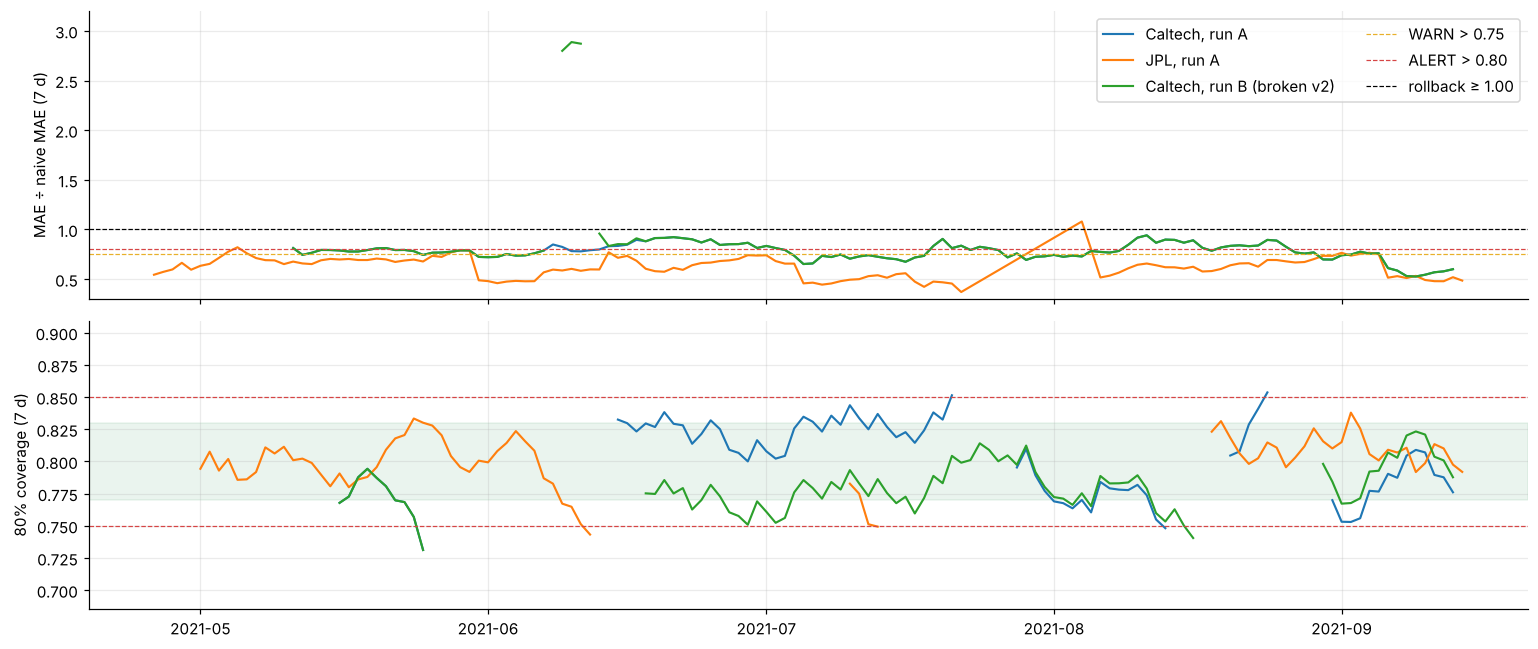

,day,version,ratio_7d,coverage_7d,actions
15,2021-05-25,v1,0.743494,0.731213,RECALIBRATE (avg offset +0.22 cars)
22,2021-06-01,v1,0.720944,0.856213,RECALIBRATE (avg offset +0.04 cars)
29,2021-06-08,v2,NaN,NaN,release v2
32,2021-06-11,v2,2.870906,NaN,ROLLBACK v2 -> v1
36,2021-06-15,v1,0.852604,NaN,PAGE: below target 3 days -> retraining ticket
72,2021-07-21,v1,0.811978,0.804315,PAGE: below target 3 days -> retraining ticket
93,2021-08-11,v1,0.941102,0.778925,PAGE: below target 3 days -> retraining ticket
98,2021-08-16,v1,0.890973,0.740513,RECALIBRATE (avg offset +0.26 cars)
103,2021-08-21,v1,0.840454,NaN,PAGE: below target 3 days -> retraining ticket
105,2021-08-23,v1,0.838281,0.852400,RECALIBRATE (avg offset +0.04 cars)


In [29]:
mq = {"Caltech, run A": "model_quality_daily_caltech", "JPL, run A": "model_quality_daily_jpl",
      "Caltech, run B (broken v2)": "model_quality_daily_caltech_bad_release"}
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for label, f in mq.items():
    q = pd.read_csv(f"outputs/monitoring/{f}.csv")
    q["day"] = pd.to_datetime(q["day"].str[:10])
    ax[0].plot(q["day"], q["ratio_7d"], label=label, lw=1.4)
    ax[1].plot(q["day"], q["coverage_7d"], label=label, lw=1.4)
for yv, c, t in [(0.75, "#e8b02b", "WARN > 0.75"), (0.80, "#d64545", "ALERT > 0.80"), (1.00, "k", "rollback ≥ 1.00")]:
    ax[0].axhline(yv, color=c, ls="--", lw=0.8, label=t)
ax[1].axhspan(0.77, 0.83, color="#3a9a5b", alpha=0.1); ax[1].axhline(0.75, color="#d64545", ls="--", lw=0.8); ax[1].axhline(0.85, color="#d64545", ls="--", lw=0.8)
ax[0].set_ylabel("MAE ÷ naive MAE (7 d)"); ax[1].set_ylabel("80% coverage (7 d)"); ax[0].legend(loc="upper right", ncol=2)
ax[0].set_ylim(0.3, 3.2); plt.tight_layout(); plt.show()

bad = pd.read_csv("outputs/monitoring/model_quality_daily_caltech_bad_release.csv")
bad.loc[bad["actions"].notna(), ["day", "version", "ratio_7d", "coverage_7d", "actions"]].assign(day=lambda x: x["day"].str[:10])

---
## 9 · Drift and continual learning (Jamal)
Retrain on alerts, prove the new model in shadow, then promote. Replay of 127 days at JPL with two drifts: a phase shift (a time-of-use tariff moves arrivals 2.5 h later, 18 Dec) and a structural surge (1.75× demand from 1 Jan). Saved results of `continual_learning_hit.py`, 3 seeds.

In [30]:
summ = pd.read_csv("outputs/continual/summary_jpl.csv").set_index("setup")
summ[["MAE", "coverage", "models trained", "deployed", "rejected", "right decisions"]].round(3)

,MAE,coverage,models trained,deployed,rejected,right decisions
setup,,,,,,
stale,2.578,0.770,0.000,0.000,0.000,–
scheduled,2.610,0.784,18.000,18.000,0.000,–
triggered,2.615,0.791,11.000,11.000,0.000,–
gated,2.815,0.785,8.000,5.000,2.000,13 / 21
gated + random review,2.548,0.795,8.000,1.667,6.333,17 / 23
gated + disagreement review,2.536,0.792,7.667,2.667,5.000,20 / 23
gated + review all,2.813,0.788,7.333,3.667,3.667,17 / 22


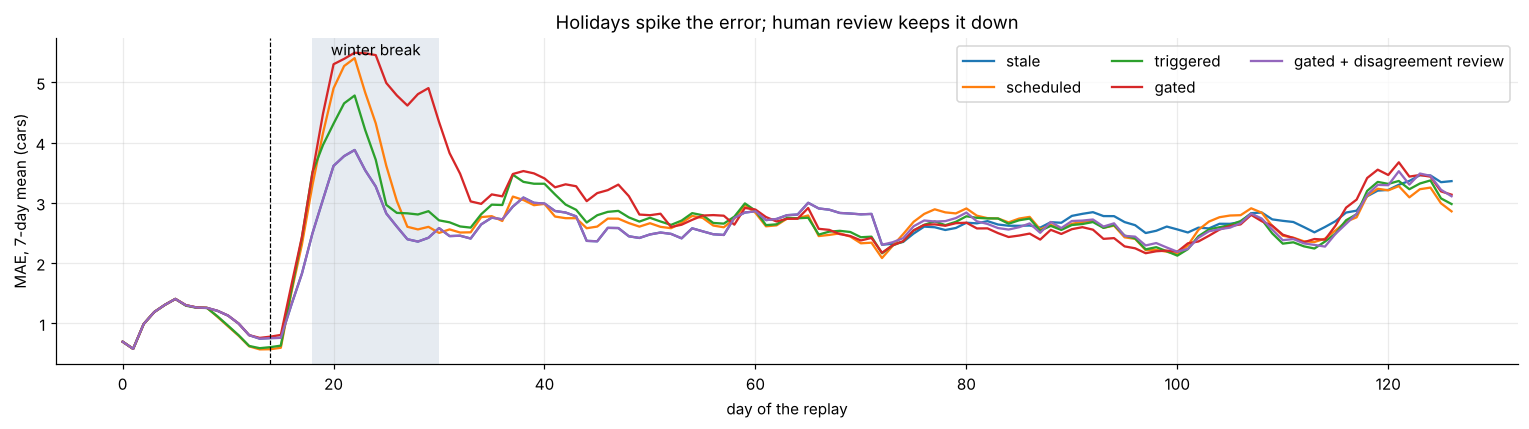

In [31]:
daily = pd.read_csv("outputs/continual/daily_jpl.csv")
daily["setup"] = daily["policy"] + np.where(daily["review"] == "none", "", " + " + daily["review"] + " review")
g = daily.groupby(["setup", "day"])[["err", "n"]].sum()
mae_day = (g["err"] / g["n"]).unstack(0)
fig, ax = plt.subplots(figsize=(14, 4))
for col in ["stale", "scheduled", "triggered", "gated", "gated + disagreement review"]:
    ax.plot(mae_day.index, mae_day[col].rolling(7, min_periods=1).mean(), label=col, lw=1.5)
ax.axvspan(18, 30, color="#9fb0c8", alpha=0.25, lw=0); ax.text(24, ax.get_ylim()[1] * 0.95, "winter break", ha="center")
ax.axvline(14, color="k", ls="--", lw=0.8)
ax.set_xlabel("day of the replay"); ax.set_ylabel("MAE, 7-day mean (cars)")
ax.set_title("Holidays spike the error; human review keeps it down"); ax.legend(ncol=3)
plt.tight_layout(); plt.show()

* **Shifts fix themselves, surges don't:** the 7-day input absorbs a 2.5 h shift; a 1.75× surge needs new weights.
* **Holidays poison the gate:** without review, holiday-trained challengers win the shadow comparison and go live; with review they are rejected.

---
## 10 · Human in the loop and active learning (Kaoutar, Jamal)
Labels arrive on their own; humans judge what is **normal**. Each evening of a shadow week, the operator reviews the 2 forecasts where champion and challenger disagree most (query by committee), 14 reviews per challenger. A day tagged abnormal leaves the comparison and all future training.

In [32]:
eff = pd.read_csv("outputs/continual/effort_jpl.csv")
weeks = 127 / 7
hours = eff.groupby(["policy", "review"])["operator minutes"].mean() / 60 / weeks
ops = pd.DataFrame({
    "operator": ["None (gate only)", "Random review", "Disagreement review", "Review everything"],
    "setup": ["gated", "gated + random review", "gated + disagreement review", "gated + review all"],
    "hours / week": [hours[("gated", r)] for r in ["none", "random", "disagreement", "all"]],
})
ops["right decisions"] = ops["setup"].map(summ["right decisions"])
ops["MAE"] = ops["setup"].map(summ["MAE"])
ops.drop(columns="setup").set_index("operator").round(3)

,hours / week,right decisions,MAE
operator,,,
None (gate only),0.000,13 / 21,2.815
Random review,0.437,17 / 23,2.548
Disagreement review,0.421,20 / 23,2.536
Review everything,13.704,17 / 22,2.813


**25 minutes of human time a week fixes the gate.** More review is not better: with a 5% operator error, reviewing everything falsely quarantines normal windows, so MAE gets worse at about 30× the time.

The second simulation (`hitl_active_learning.ipynb`) adds sensor faults and compares which windows the operator should check: `surprise` (forecast far from the truth) finds faulty windows best.

In [33]:
pd.read_csv("outputs/hitl/hitl_summary_jpl.csv", index_col=0).round(3)

,MAE,damage removed (%),faults fixed (%),checks that found a fault (%),operator h/week
no_human,1.864,0.000,0.000,NaN,0.000
stale,1.523,NaN,0.000,NaN,0.000
"random, 3/week",1.814,13.606,7.165,19.444,0.150
"uncertainty, 3/week",1.830,9.137,7.433,19.444,0.150
"surprise, 3/week",1.849,4.120,7.055,9.722,0.150
"random, 7/week",1.783,22.096,14.168,13.690,0.350
"uncertainty, 7/week",1.827,10.160,13.200,14.881,0.350
"surprise, 7/week",1.799,17.801,20.598,17.262,0.350
"random, 14/week",1.747,32.009,31.337,13.690,0.700
"uncertainty, 14/week",1.766,26.795,17.722,14.286,0.700


---
## Summary
| | Result |
|---|---|
| Data | 44,989 sessions → one row every 15 min → ~80k windows per site, split by time |
| Model | DLinear: 64,626 parameters, ~0.15 ms per forecast on CPU, beats both naive baselines |
| Intervals | CQR brings 80% coverage from ~61–70% raw to ~77–80% |
| Ensemble | + Ridge: 15-min error down 6% (Caltech) and 20% (JPL) |
| Robustness | fine with missing values and calendar loss; fragile to wrong values and attacks → sanitizer, abstention, monitoring |
| Monitoring | every injected data fault caught in its week; drift: shift = WARN only, ×1.75 surge = 4 weeks of ALERT; broken release rolled back after 3 days |
| Continual learning + HITL | review of 14 disputed forecasts per challenger keeps holiday models out, ~0.4 h/week |